In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.random.seed(10)

c:\Users\msado\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


# Implementacja sieci

In [2]:
class sigmoid():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01

    def forward(self, x):
        self.out = 1 / (1 + np.exp(-x))
        return self.out

    def backward(self, grad_output):
        # f'(x) = f(x) * (1 - f(x)) 
        return grad_output * self.out * (1 - self.out)

In [3]:
class relu():
    def __init__(self):
        self.input = None
        self.learning_rate = 0.01

    def forward(self, x):
        self.input = x
        return np.maximum(0, x)
    
    def backward(self, grad_output):
        grad_input = grad_output.copy()
        grad_input[self.input <= 0] = 0
        return grad_input

In [4]:
class MSE:
    def __init__(self):
        self.cache_y_pred = None
        self.cache_y_true = None
        
    def forward(self, y_pred, y_true):
        self.cache_y_pred = y_pred
        self.cache_y_true = y_true
        return np.mean((y_pred - y_true) ** 2)
        
    def backward(self):
        return (self.cache_y_pred - self.cache_y_true)

In [5]:
class warstwa_liniowa():
    def __init__(self, liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych, inicjalizacja):
        self.liczba_neuronow_wejsciowych = liczba_neuronow_wejsciowych
        self.liczba_neuronow_wyjsciowych = liczba_neuronow_wyjsciowych

        # inicjalizacja wag za pomocą Xaviera
        if inicjalizacja == 'xavier':
            a = -np.sqrt(6/(liczba_neuronow_wejsciowych+liczba_neuronow_wyjsciowych))
            b = -a
        # inicjalizacja wag za pomocą He
        elif inicjalizacja == 'he':
            a = -np.sqrt(6/liczba_neuronow_wejsciowych)
            b = -a
        else:
            a = 0
            b = 1
        self.wagi = np.random.uniform(a, b, (liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych))
        self.bias = np.zeros((1, liczba_neuronow_wyjsciowych))

        self.input = None
        self.grad_wagi = None
        self.grad_bias = None

        self.learning_rate = 0.01

    def forward(self, x):
        # x - neurony wejsciowe, wektor o dlugosci = liczba_neuronow_wejsciowych
        self.input = x
        return np.dot(x, self.wagi) + self.bias
    
    def backward(self, grad_output):
        # L - funkcja straty
        # grad_output = dL/dY
        # input = x
        
        N = len(self.input)

        # dL/dX
        grad_input = np.dot(grad_output, self.wagi.T)
        # dL/dW
        self.grad_wagi = np.dot(self.input.T, grad_output) / N
        # dL/db
        self.grad_bias = np.sum(grad_output, axis=0, keepdims=True) / N

        return grad_input
    
    def update(self):
        N = len(self.input)
        self.wagi -= self.learning_rate * self.grad_wagi
        self.bias -= self.learning_rate * self.grad_bias

In [6]:
class MLP():
    def __init__(self, warstwy, learning_rate):
        self.warstwy = warstwy # lista obiektów warstwa_liniowa i funkcji aktywacji
        self.learning_rate = learning_rate
        for warstwa in self.warstwy:
            warstwa.learning_rate = self.learning_rate

    def forward(self, x):
        for warstwa in self.warstwy:
            x = warstwa.forward(x)
        return x
    
    def backward(self, grad_output):
        for warstwa in reversed(self.warstwy):
            grad_output = warstwa.backward(grad_output)
        return grad_output
    
    def update(self):
        for warstwa in self.warstwy:
            if hasattr(warstwa, 'update'):
                warstwa.update()

# Zmiana wag propagacją wsteczną

In [20]:
def train(X_train, y_train, X_test, y_test, model, epoki, rozmiar_batcha, funkcja_straty=MSE, test=False):
    x_min = X_train.min(axis=0)
    x_max = X_train.max(axis=0)
    y_min = y_train.min(axis=0)
    y_max = y_train.max(axis=0)

    X_train_scaled = (X_train - x_min) / (x_max - x_min)
    y_train_scaled = (y_train - y_min) / (y_max - y_min)
    X_test_scaled = (X_test - x_min) / (x_max - x_min)
    y_test_scaled = (y_test - y_min) / (y_max - y_min)
    
    N = y_train.shape[0] 

    strata = funkcja_straty()

    hist_wagi = {i: [] for i, w in enumerate(model.warstwy) if hasattr(w, 'wagi')}
    historia = []

    for i in range(epoki):
        # Tasowanie danych i pętla po małych porcjach
        indeksy = np.random.permutation(N)
        X_shuffled = X_train_scaled[indeksy]
        y_shuffled = y_train_scaled[indeksy]

        epoch_loss = 0
        
        for start in range(0, N, rozmiar_batcha):
            koniec = start + rozmiar_batcha
            X_batch = X_shuffled[start:koniec]
            y_batch = y_shuffled[start:koniec]
            
            # Przejście dla batcha
            y_pred_batch = model.forward(X_batch)

            # Obliczenie straty dla batcha
            loss = strata.forward(y_pred_batch, y_batch)
            epoch_loss += loss * len(X_batch)

            # Wsteczna propagacja i aktualizacja wag
            grad_output = strata.backward()
            model.backward(grad_output)
            model.update()

        avg_loss = epoch_loss / N
        historia.append(avg_loss)

        for idx, warstwa in enumerate(model.warstwy):
            if hasattr(warstwa, 'wagi'):
                hist_wagi[idx].append(warstwa.wagi.copy())
        
        # Wyświetlanie błędu dla całego zbioru co 1000 epok
        if test and i % 1000 == 0:
            y_pred_all = model.forward(X_train_scaled)
            y_pred_unscaled = y_pred_all * (y_max - y_min) + y_min
            mse_nieznormalizowane = strata.forward(y_pred_unscaled, y_train)
            print(f"Krok {i}, Strata (nieznormalizowana): {mse_nieznormalizowane:.4f}")

    
    y_pred_all = model.forward(X_train_scaled)
    y_pred_unscaled = y_pred_all * (y_max - y_min) + y_min
    mse_nieznormalizowane = strata.forward(y_pred_unscaled, y_train)
    print(f"MSE treningowe FINALNE: {mse_nieznormalizowane:.4f}")

    y_pred_test_scaled = model.forward(X_test_scaled)
    y_pred_test = y_pred_test_scaled * (y_max - y_min) + y_min
    mse_test = strata.forward(y_pred_test, y_test)
    print(f"MSE testowe FINALNE: {mse_test:.4f}")

    # Rysowanie wykresów wag
    numer_warstwy = 1
    for idx, hist in hist_wagi.items():
        plt.figure(figsize=(10, 5))
        
        historia_np = np.array(hist)
        epoki_w_historii = historia_np.shape[0]
        wejscia = historia_np.shape[1]
        wyjscia = historia_np.shape[2]
        
        for wej in range(wejscia):
            for wyj in range(wyjscia):
                plt.plot(range(epoki_w_historii), historia_np[:, wej, wyj], label=f'Waga wej:{wej}->wyj:{wyj}')
        
        plt.title(f'Zmiana wag w czasie - Warstwa Liniowa {numer_warstwy}')
        plt.xlabel('Epoka')
        plt.ylabel('Wartość wagi')
            
        plt.tight_layout()
        plt.show()
        numer_warstwy += 1

    # Rysowanie wykresu dopasowania modelu
    plt.figure(figsize=(8, 6))
    plt.scatter(X_test, y_test, color='blue', label='Prawdziwa wartość')
    plt.scatter(X_test, y_pred_test, color='orange', label='Przewidziana wartość')
    plt.legend()
    plt.title('Wartości na zbiorze testowym')
    plt.show()
    
    # return historia

# Dane square simple

In [8]:
square_simple_test = pd.read_csv("mio1/regression/square-simple-test.csv")
square_simple_train = pd.read_csv("mio1/regression/square-simple-training.csv")
X_train = square_simple_train[['x']].to_numpy()
y_train = square_simple_train[['y']].to_numpy()
X_test = square_simple_test[['x']].to_numpy()
y_test = square_simple_test[['y']].to_numpy()

## Aktualizacja na koniec

In [18]:
np.random.seed(10)
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.5)

Krok 0, Strata (nieznormalizowana): 9347.2193
Krok 1000, Strata (nieznormalizowana): 7516.6941
Krok 2000, Strata (nieznormalizowana): 7168.5144
Krok 3000, Strata (nieznormalizowana): 6545.1190
Krok 4000, Strata (nieznormalizowana): 4926.7475
Krok 5000, Strata (nieznormalizowana): 845.7584
Krok 6000, Strata (nieznormalizowana): 157.9215
Krok 7000, Strata (nieznormalizowana): 109.4161
Krok 8000, Strata (nieznormalizowana): 89.5556
Krok 9000, Strata (nieznormalizowana): 75.6626
Krok 10000, Strata (nieznormalizowana): 64.9948
Krok 11000, Strata (nieznormalizowana): 56.4315
Krok 12000, Strata (nieznormalizowana): 49.3634
Krok 13000, Strata (nieznormalizowana): 43.4185
Krok 14000, Strata (nieznormalizowana): 38.3513
Krok 15000, Strata (nieznormalizowana): 33.9898
Krok 16000, Strata (nieznormalizowana): 30.2083
Krok 17000, Strata (nieznormalizowana): 26.9114
Krok 18000, Strata (nieznormalizowana): 24.0246
Krok 19000, Strata (nieznormalizowana): 21.4882
Krok 20000, Strata (nieznormalizowana): 

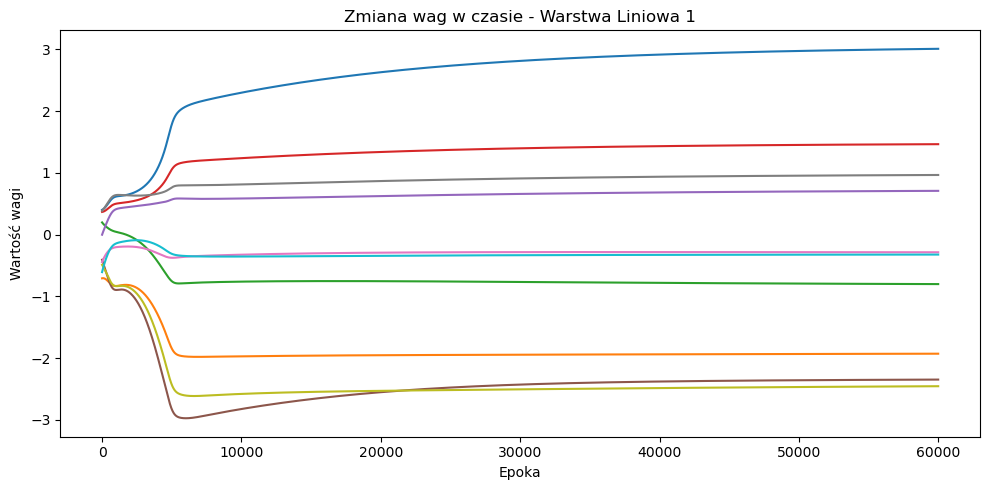

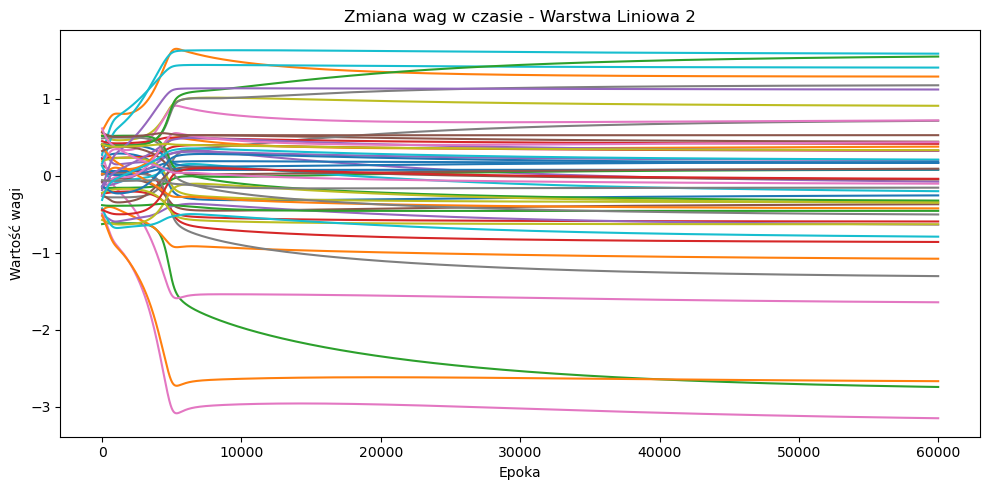

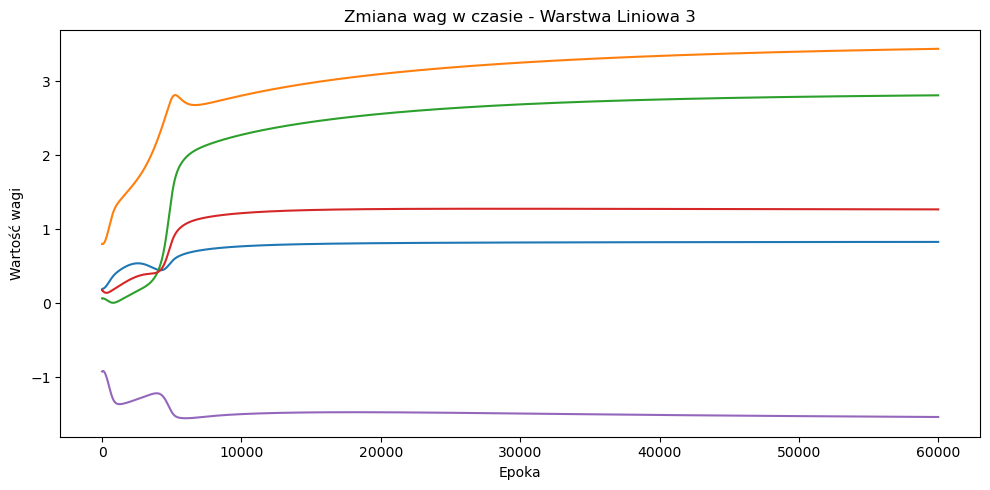

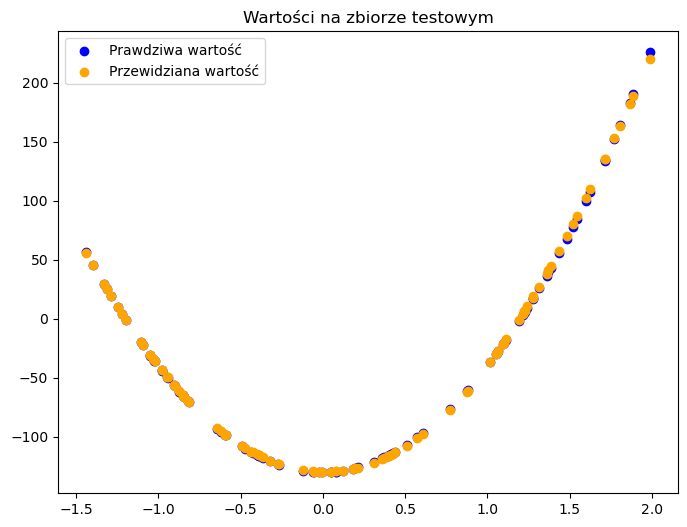

In [ ]:
np.random.seed(10)
train(X_train, y_train, X_test, y_test, model, 60000, y_train.shape[0])

## Aktualizacja w batchach

In [21]:
np.random.seed(10)
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.2)

Krok 0, Strata (nieznormalizowana): 9628.1515
Krok 1000, Strata (nieznormalizowana): 6583.6186
Krok 2000, Strata (nieznormalizowana): 168.6161
Krok 3000, Strata (nieznormalizowana): 78.4780
Krok 4000, Strata (nieznormalizowana): 37.4855
Krok 5000, Strata (nieznormalizowana): 24.5878
Krok 6000, Strata (nieznormalizowana): 16.9959
Krok 7000, Strata (nieznormalizowana): 13.6839
Krok 8000, Strata (nieznormalizowana): 10.9149
Krok 9000, Strata (nieznormalizowana): 7.1196
Krok 10000, Strata (nieznormalizowana): 5.9593
Krok 11000, Strata (nieznormalizowana): 3.9109
Krok 12000, Strata (nieznormalizowana): 3.1993
Krok 13000, Strata (nieznormalizowana): 2.7259
Krok 14000, Strata (nieznormalizowana): 2.7133
Krok 15000, Strata (nieznormalizowana): 2.7021
Krok 16000, Strata (nieznormalizowana): 1.8549
Krok 17000, Strata (nieznormalizowana): 2.0706
Krok 18000, Strata (nieznormalizowana): 1.6346
Krok 19000, Strata (nieznormalizowana): 2.0033
MSE treningowe FINALNE: 1.6586
MSE testowe FINALNE: 1.4922


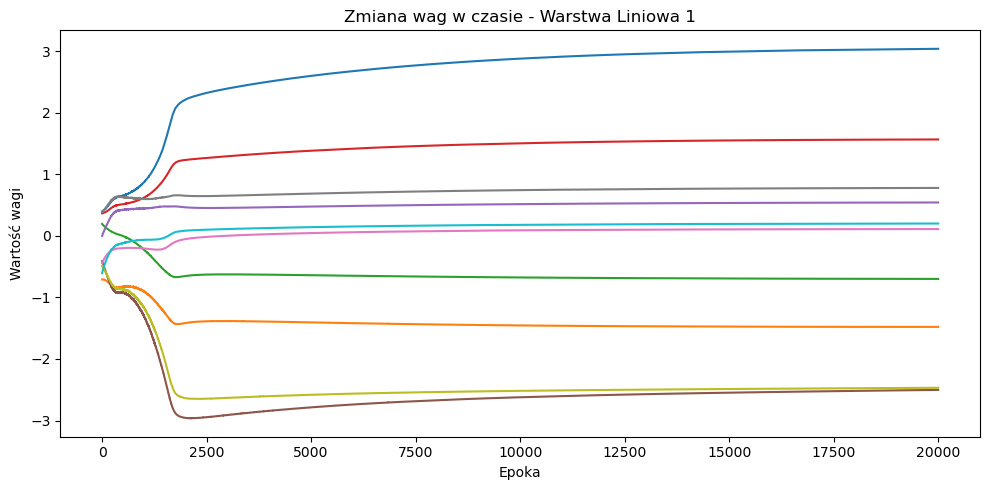

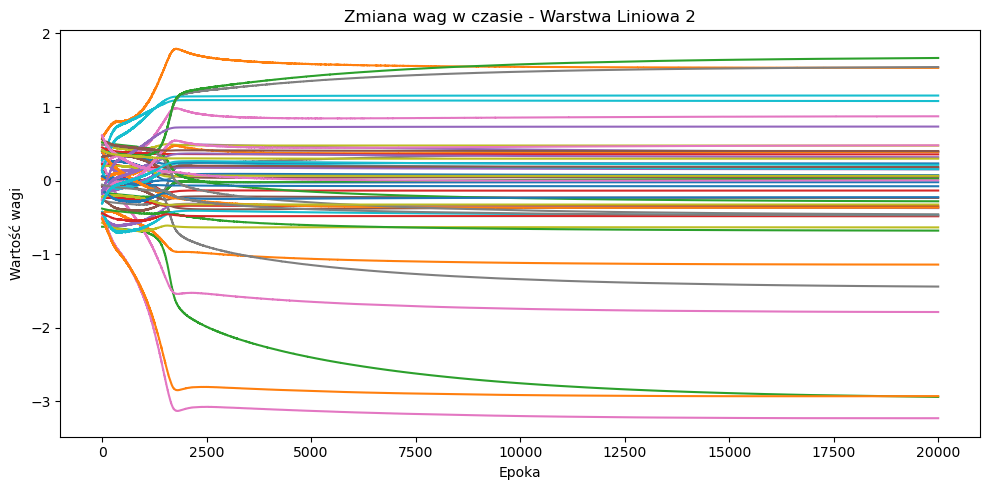

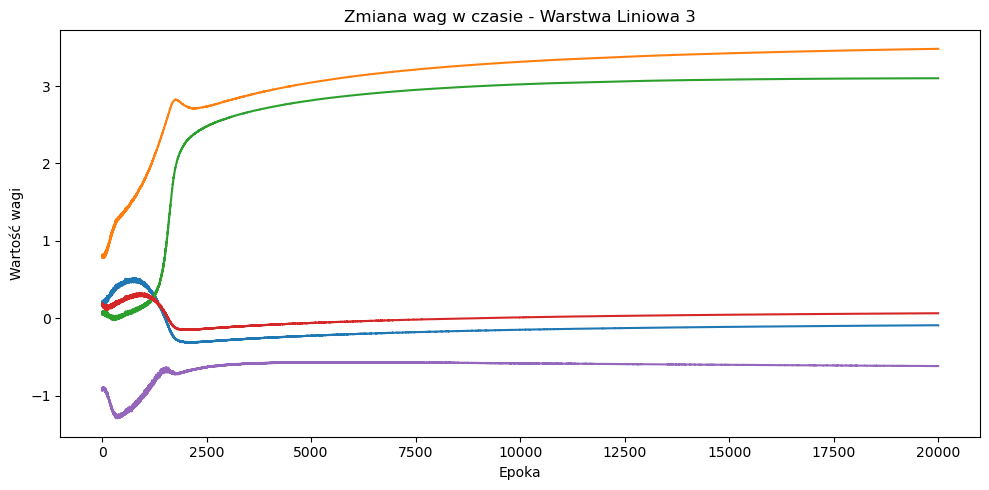

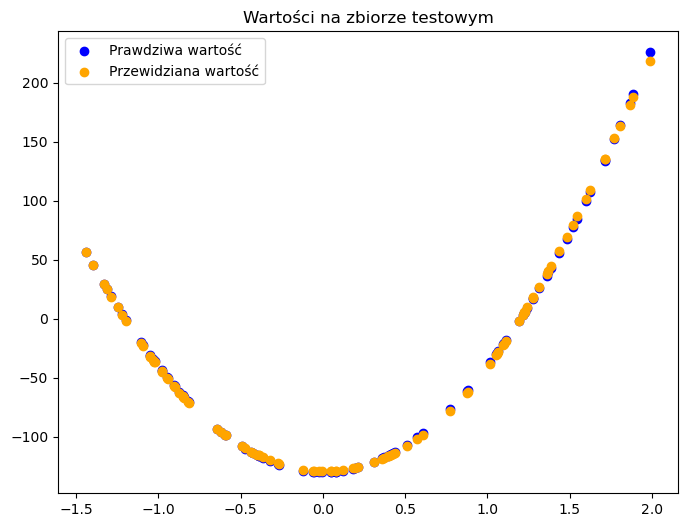

In [22]:
np.random.seed(10)
train(X_train, y_train, X_test, y_test, model, 20000, 16, test=True)

# Dane steps small

In [23]:
steps_small_test = pd.read_csv("mio1/regression/steps-small-test.csv")
steps_small_train = pd.read_csv("mio1/regression/steps-small-training.csv")
X_train = steps_small_train[['x']].to_numpy()
y_train = steps_small_train[['y']].to_numpy()
X_test = steps_small_test[['x']].to_numpy()
y_test = steps_small_test[['y']].to_numpy()

## Aktualizacja na koniec

In [26]:
np.random.seed(10)
warstwa_1 = warstwa_liniowa(1, 6, 'he')
warstwa_2 = warstwa_liniowa(6, 4, 'xavier')
warstwa_3 = warstwa_liniowa(4, 1, 'xavier')
model = MLP((warstwa_1, relu(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.6)

In [27]:
np.random.seed(10)
train(X_train, y_train, X_test, y_test, model, 6000000, y_train.shape[0], test=True)

Krok 0, Strata (nieznormalizowana): 5358.9951
Krok 1000, Strata (nieznormalizowana): 358.5853
Krok 2000, Strata (nieznormalizowana): 353.2250
Krok 3000, Strata (nieznormalizowana): 350.4760
Krok 4000, Strata (nieznormalizowana): 348.7997
Krok 5000, Strata (nieznormalizowana): 347.6542
Krok 6000, Strata (nieznormalizowana): 346.8131
Krok 7000, Strata (nieznormalizowana): 346.1764
Krok 8000, Strata (nieznormalizowana): 345.6736
Krok 9000, Strata (nieznormalizowana): 345.2625
Krok 10000, Strata (nieznormalizowana): 344.9182
Krok 11000, Strata (nieznormalizowana): 344.6245
Krok 12000, Strata (nieznormalizowana): 344.3708
Krok 13000, Strata (nieznormalizowana): 344.1490
Krok 14000, Strata (nieznormalizowana): 343.9533
Krok 15000, Strata (nieznormalizowana): 343.7787
Krok 16000, Strata (nieznormalizowana): 343.6225
Krok 17000, Strata (nieznormalizowana): 343.4867
Krok 18000, Strata (nieznormalizowana): 343.3656
Krok 19000, Strata (nieznormalizowana): 343.2568
Krok 20000, Strata (nieznormaliz

KeyboardInterrupt: 

## Aktualizacja w batchach

In [55]:
np.random.seed(10)
warstwa_1 = warstwa_liniowa(1, 6, 'he')
warstwa_2 = warstwa_liniowa(6, 4, 'xavier')
warstwa_3 = warstwa_liniowa(4, 1, 'xavier')
model = MLP((warstwa_1, relu(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.1)

MSE treningowe: 0.14545464457512788
MSE testowe: 8.00170975686319


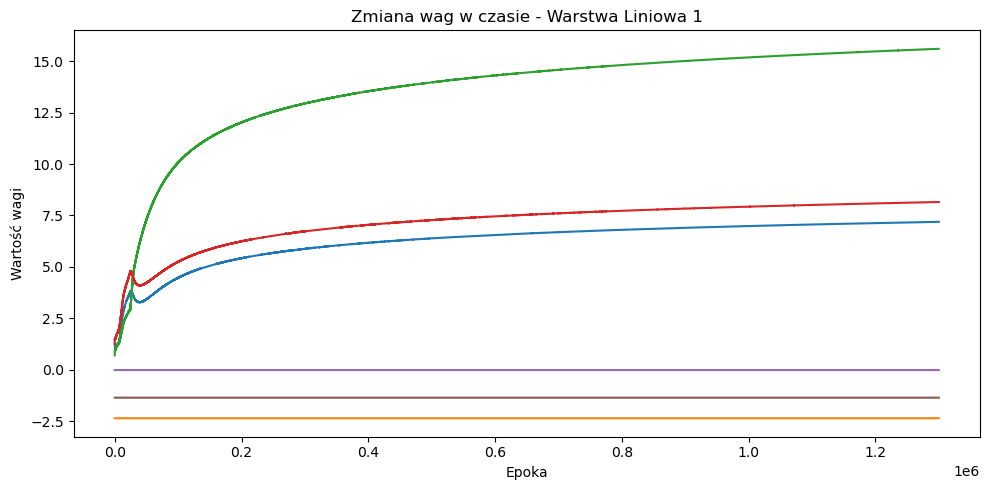

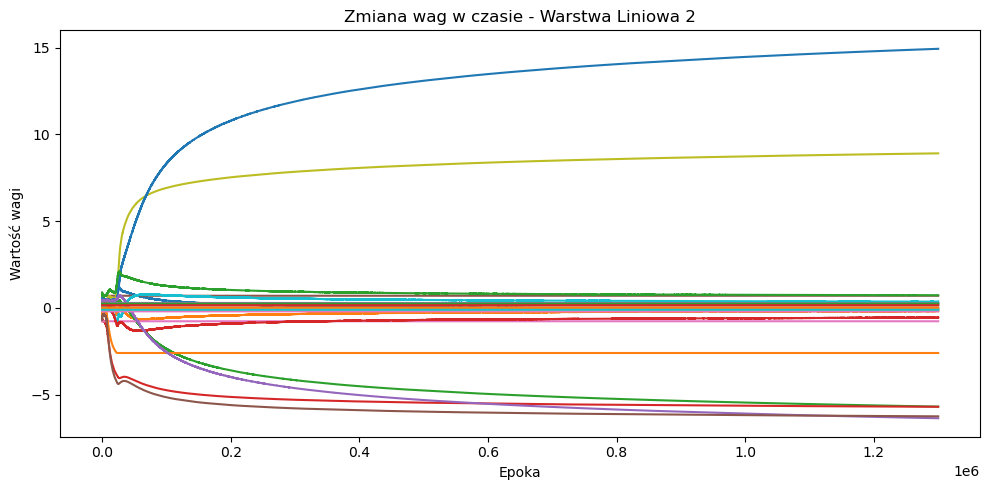

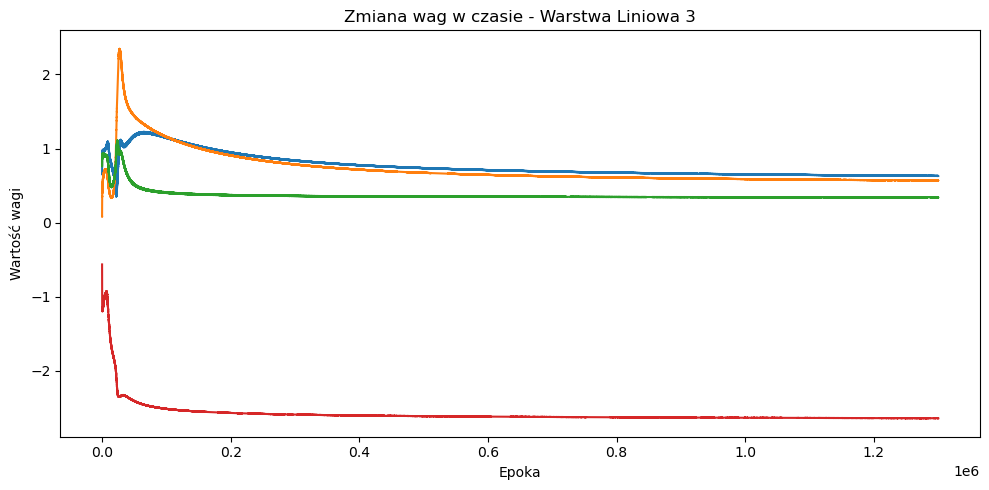

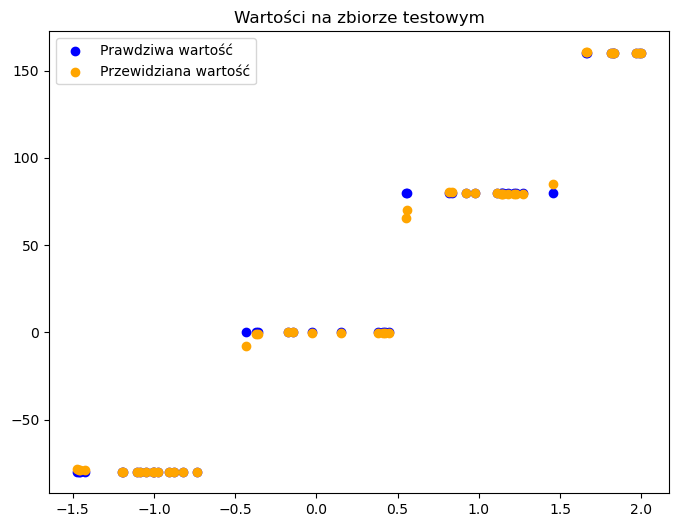

In [56]:
np.random.seed(10)
train(X_train, y_train, X_test, y_test, model, 1300000, 2)

# Dane multimodal large

In [57]:
multimodal_large_test = pd.read_csv("mio1/regression/multimodal-large-test.csv")
multimodal_large_train = pd.read_csv("mio1/regression/multimodal-large-training.csv")
X_train = multimodal_large_train[['x']].to_numpy()
y_train = multimodal_large_train[['y']].to_numpy()
X_test = multimodal_large_test[['x']].to_numpy()
y_test = multimodal_large_test[['y']].to_numpy()

## Aktualizacja na koniec

In [58]:
np.random.seed(10)
warstwa_1 = warstwa_liniowa(1, 4, 'he')
warstwa_2 = warstwa_liniowa(4, 9, 'xavier')
warstwa_3 = warstwa_liniowa(9, 1, 'xavier')
model = MLP((warstwa_1, relu(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.4)

MSE treningowe: 22.80253643040777
MSE testowe: 17.458028143549505


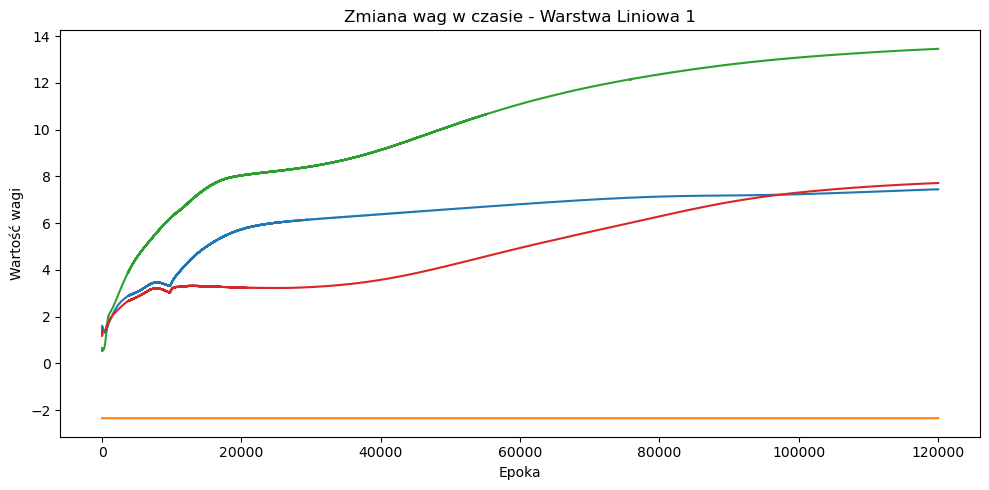

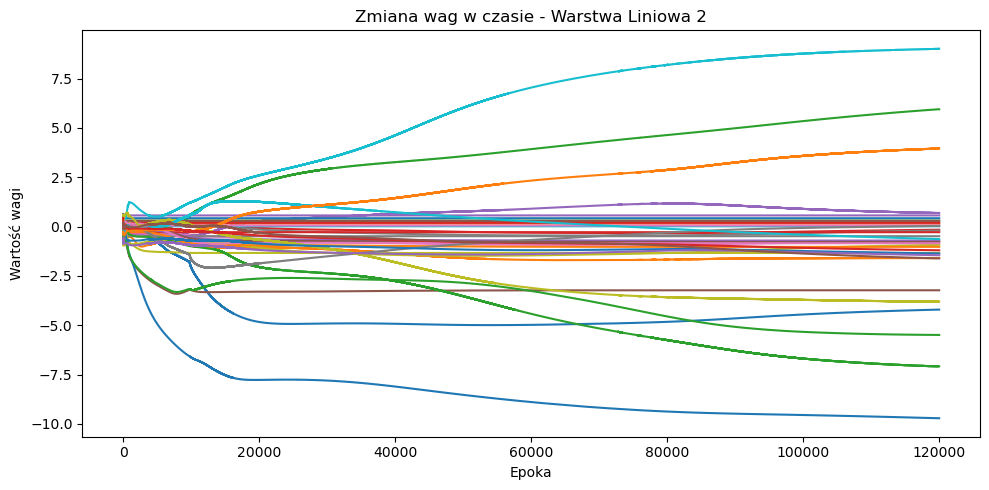

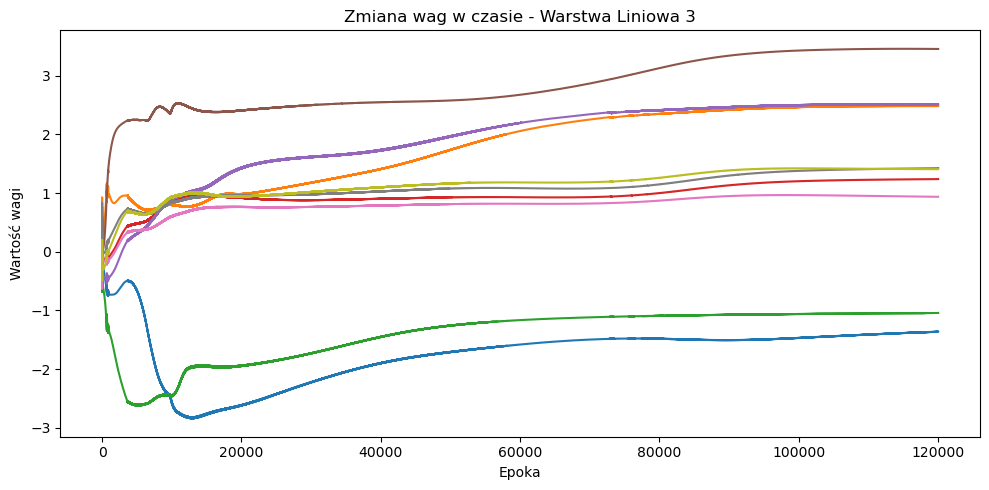

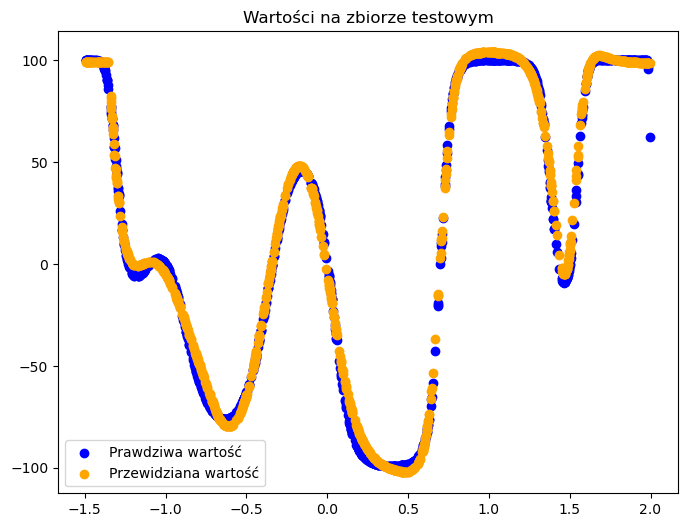

In [59]:
np.random.seed(10)
train(X_train, y_train, X_test, y_test, model, 120000, y_train.shape[0])

## Aktualizacja w batchach

In [60]:
np.random.seed(10)
warstwa_1 = warstwa_liniowa(1, 4, 'he')
warstwa_2 = warstwa_liniowa(4, 9, 'xavier')
warstwa_3 = warstwa_liniowa(9, 1, 'xavier')
model = MLP((warstwa_1, relu(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.3)

MSE treningowe: 12.069391516107514
MSE testowe: 7.337377382607177


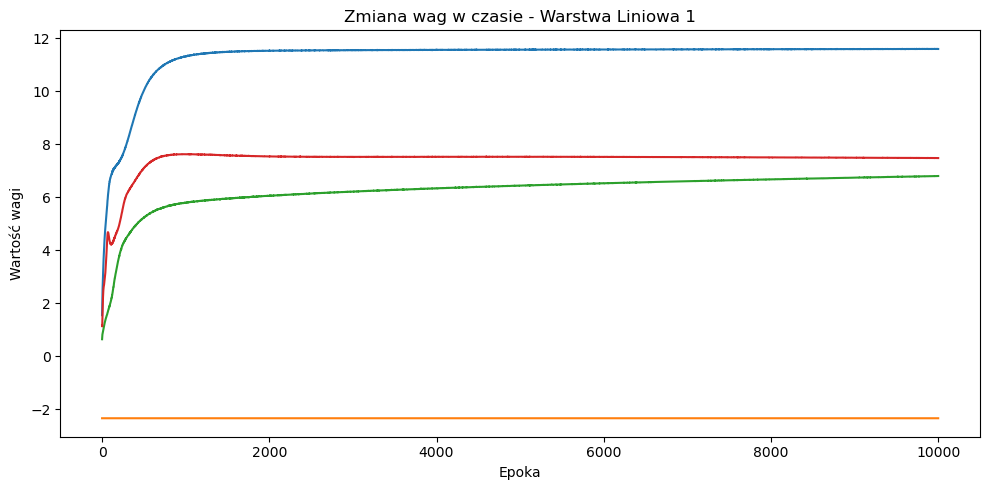

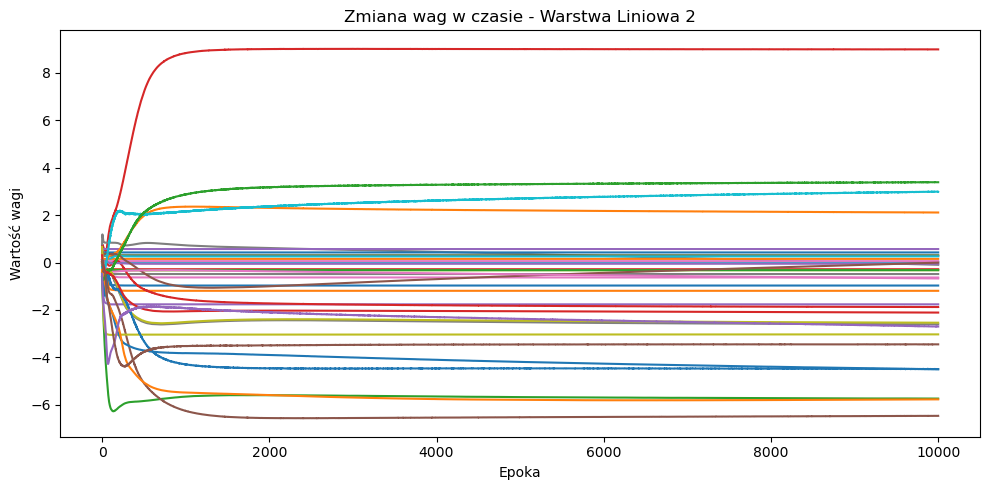

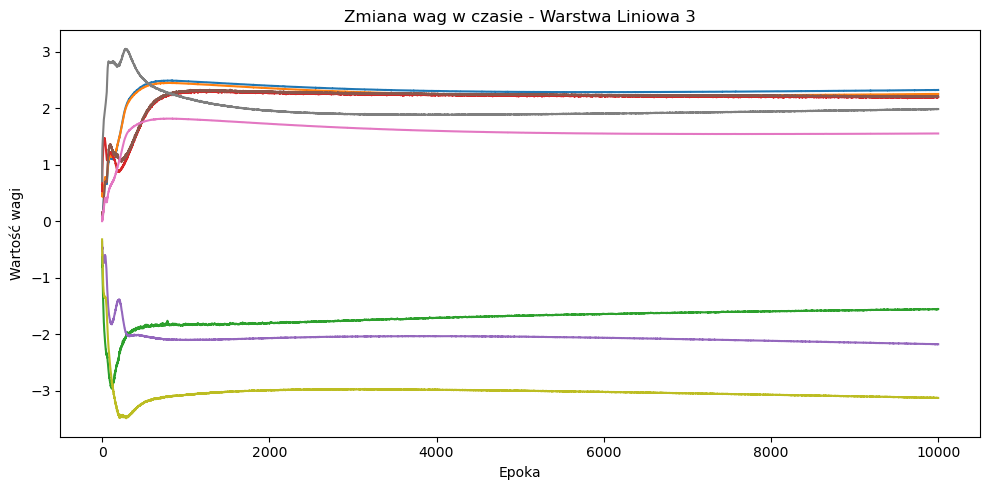

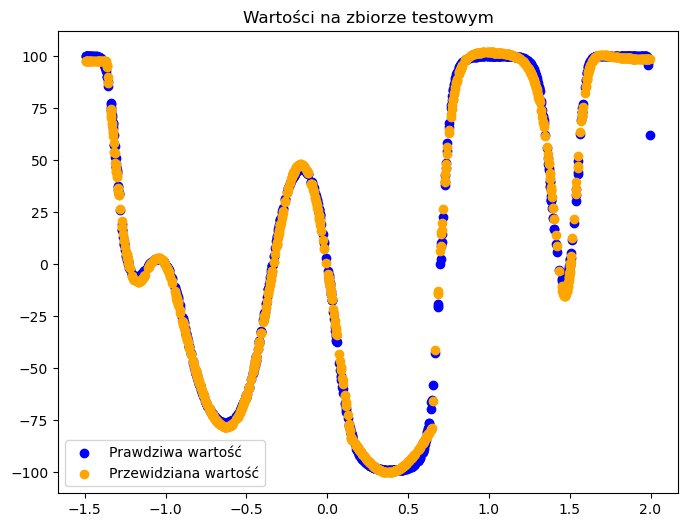

In [61]:
np.random.seed(10)
train(X_train, y_train, X_test, y_test, model, 10000, 64)